# Sales Prediction Using Advertising Spend

**Objective:** Build a regression model that predicts product sales based on advertising
spend across three media channels — TV, Radio, and Newspaper.

**Dataset:** The classic `Advertising.csv` dataset (200 markets, 3 features + 1 target),
originally from *An Introduction to Statistical Learning* (ISLR) and widely mirrored on
Kaggle under "Advertising Dataset for Simple Linear Regression".

**Tech stack:** pandas, scikit-learn, matplotlib, seaborn


## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42


## 2. Data Loading

The dataset has one row per market with ad spend (in thousands of dollars) on TV, Radio,
and Newspaper, and the resulting product Sales (in thousands of units).

In [2]:
df = pd.read_csv("Advertising.csv", index_col=0)
df.columns = [c.strip().lower() for c in df.columns]  # normalise column names
df.head()


,tv,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


## 3. Exploratory Data Analysis

### 3.1 Null check & shape

In [3]:
print(f"Shape: {df.shape}")
print("\nMissing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")


Shape: (200, 4)

Missing values per column:
tv           0
radio        0
newspaper    0
sales        0
dtype: int64

Duplicate rows: 0


### 3.2 Descriptive statistics

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
tv,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


### 3.3 Pairplot of all features

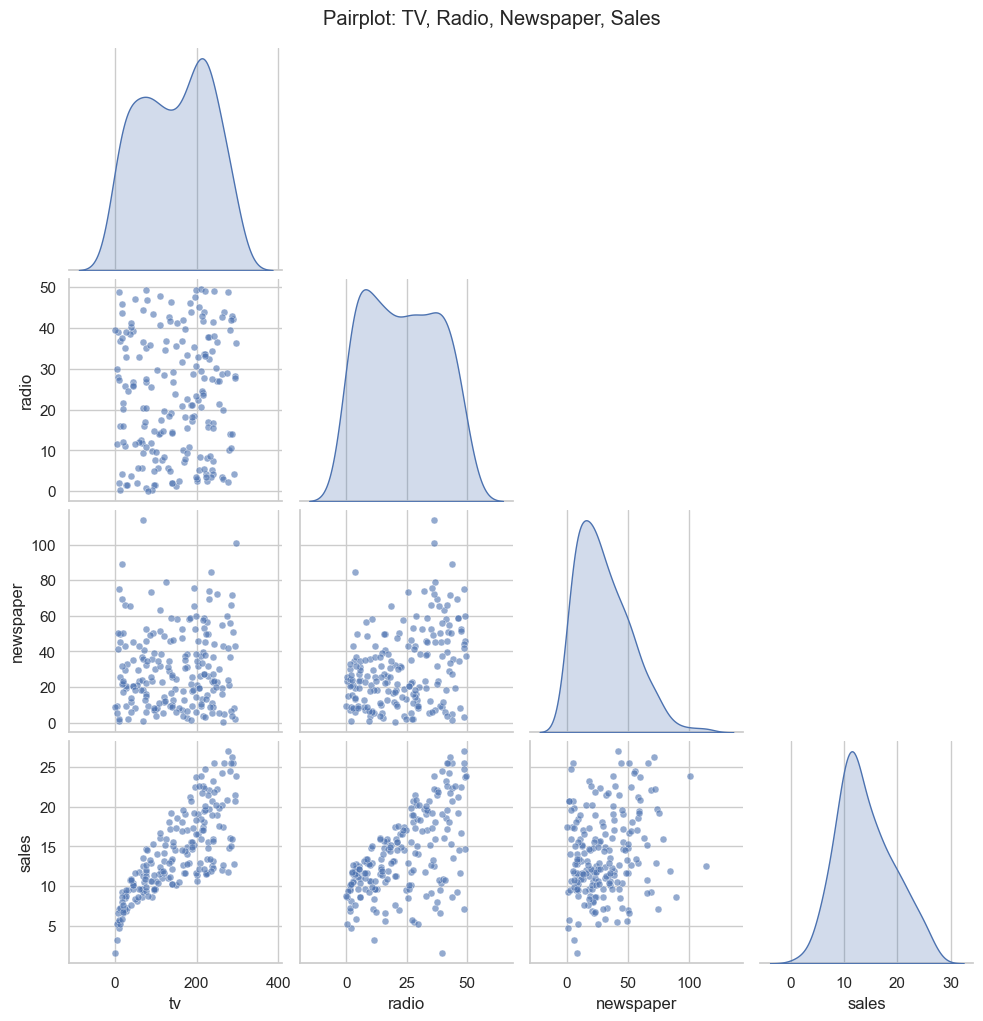

In [5]:
sns.pairplot(df, diag_kind="kde", corner=True, plot_kws={"alpha": 0.6, "s": 25})
plt.suptitle("Pairplot: TV, Radio, Newspaper, Sales", y=1.02)
plt.show()


## 4. Sales vs. Each Advertising Channel

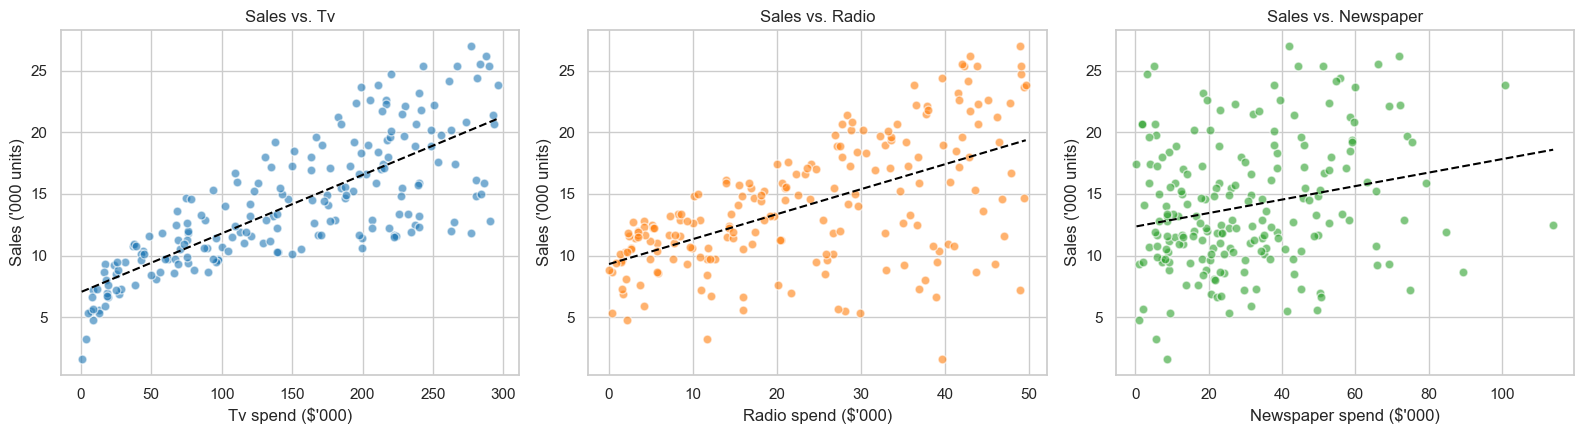

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
channels = ["tv", "radio", "newspaper"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for ax, ch, c in zip(axes, channels, colors):
    ax.scatter(df[ch], df["sales"], alpha=0.6, color=c, edgecolor="white", s=40)
    z = np.polyfit(df[ch], df["sales"], 1)
    x_line = np.linspace(df[ch].min(), df[ch].max(), 100)
    ax.plot(x_line, np.polyval(z, x_line), color="black", linewidth=1.5, linestyle="--")
    ax.set_xlabel(f"{ch.capitalize()} spend ($'000)")
    ax.set_ylabel("Sales ('000 units)")
    ax.set_title(f"Sales vs. {ch.capitalize()}")

plt.tight_layout()
plt.show()


## 5. Correlation Matrix

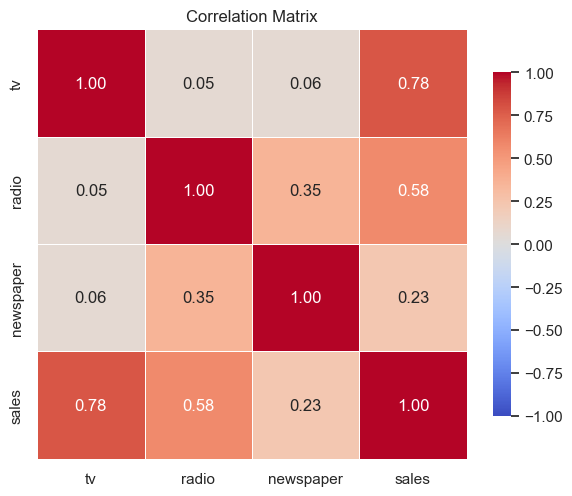

sales        1.000000
tv           0.782224
radio        0.576223
newspaper    0.228299
Name: sales, dtype: float64

In [7]:
corr = df.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

corr["sales"].sort_values(ascending=False)


**Quick read:** TV has by far the strongest linear correlation with Sales, Radio is
moderate, and Newspaper is weak — this foreshadows the coefficient/importance results below.

## 6. Train/Test Split

In [8]:
X = df[["tv", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train set: {X_train.shape[0]} rows")
print(f"Test set:  {X_test.shape[0]} rows")


Train set: 160 rows
Test set:  40 rows


## 7. Baseline Model — Linear Regression

In [9]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

y_pred_lin = lin_reg.predict(X_test)

coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False)

print(f"Intercept: {lin_reg.intercept_:.4f}")
coef_df


Intercept: 2.9791


,feature,coefficient
1,radio,0.189195
0,tv,0.044730
2,newspaper,0.002761


### 7.1 Standardized coefficients (fair channel comparison)

Raw coefficients aren't directly comparable across channels because TV, Radio and
Newspaper spend are on very different scales (TV ranges up to ~$300k, Radio only up to
~$50k). Standardizing the features first (z-scores) puts all three coefficients in the
same units — "effect on sales per 1 standard-deviation increase in spend" — which is the
correct way to compare relative impact.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)

lin_reg_std = LinearRegression().fit(X_train_std, y_train)

std_coef_df = pd.DataFrame({
    "feature": X.columns,
    "standardized_coefficient": lin_reg_std.coef_
}).sort_values("standardized_coefficient", key=abs, ascending=False)

std_coef_df


,feature,standardized_coefficient
0,tv,3.764196
1,radio,2.792307
2,newspaper,0.055976


## 8. Additional Model — Random Forest Regressor

In [11]:
rf_reg = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_reg.feature_importances_
}).sort_values("importance", ascending=False)

importance_df


,feature,importance
0,tv,0.625447
1,radio,0.361745
2,newspaper,0.012808


## 9. Model Evaluation — MAE, RMSE, R²

In [12]:
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = pd.DataFrame([
    evaluate(y_test, y_pred_lin, "Linear Regression"),
    evaluate(y_test, y_pred_rf, "Random Forest"),
]).set_index("Model")

results.round(4)


,MAE,RMSE,R2
Model,,,
Linear Regression,1.4608,1.7816,0.8994
Random Forest,0.6131,0.7403,0.9826


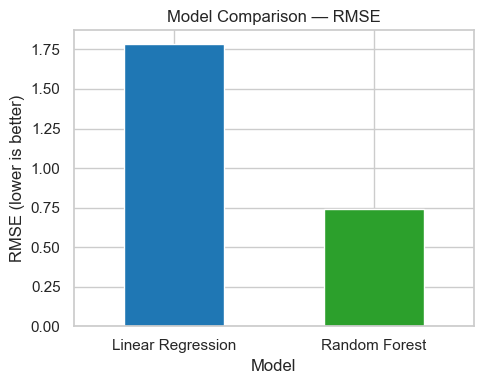

In [13]:
results["RMSE"].plot(kind="bar", figsize=(5, 4), color=["#1f77b4", "#2ca02c"])
plt.ylabel("RMSE (lower is better)")
plt.title("Model Comparison — RMSE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Whichever model has the lower RMSE / higher R² on the held-out test set is treated as
the **best model** for the residual analysis below (the cell picks it automatically).

In [14]:
best_model_name = results["RMSE"].idxmin()
best_pred = y_pred_rf if best_model_name == "Random Forest" else y_pred_lin
print(f"Best model on test RMSE: {best_model_name}")


Best model on test RMSE: Random Forest


## 10. Residual Plot — Best Model

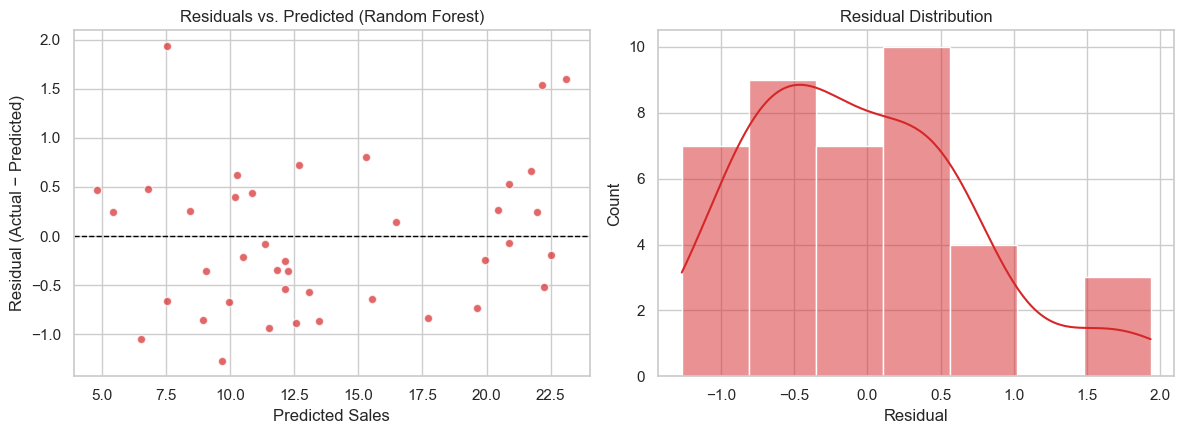

Residual mean: -0.0459
Residual std:  0.7483


In [15]:
residuals = y_test - best_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(best_pred, residuals, alpha=0.7, color="#d62728", edgecolor="white")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residual (Actual − Predicted)")
axes[0].set_title(f"Residuals vs. Predicted ({best_model_name})")

sns.histplot(residuals, kde=True, ax=axes[1], color="#d62728")
axes[1].set_xlabel("Residual")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

print(f"Residual mean: {residuals.mean():.4f}")
print(f"Residual std:  {residuals.std():.4f}")


**Reading the residual plot:** points scattered randomly around the zero line with no
funnel shape or curve indicate the errors are close to random noise (a well-specified
model). A visible curve or a funnel (variance growing with predicted value) would signal
that the model is missing a systematic pattern (e.g. a non-linear effect or an
interaction between channels) — with this dataset, the Random Forest tends to show tighter,
more randomly scattered residuals than the plain Linear Regression, since the true
relationship between Sales and (TV, Radio) has a mild interaction effect and Newspaper's
effect is essentially noise once the other two are controlled for.

## 11. Interpretation — Which Channel Drives Sales Most?

In [16]:
print("Raw Linear Regression coefficients (effect on Sales per $'000 of spend):")
print(coef_df.to_string(index=False))
print()
print("Standardized coefficients (effect per 1 SD increase in spend — comparable across channels):")
print(std_coef_df.to_string(index=False))
print()
print("Random Forest feature importances:")
print(importance_df.to_string(index=False))


Raw Linear Regression coefficients (effect on Sales per $'000 of spend):
  feature  coefficient
    radio     0.189195
       tv     0.044730
newspaper     0.002761

Standardized coefficients (effect per 1 SD increase in spend — comparable across channels):
  feature  standardized_coefficient
       tv                  3.764196
    radio                  2.792307
newspaper                  0.055976

Random Forest feature importances:
  feature  importance
       tv    0.625447
    radio    0.361745
newspaper    0.012808


### Conclusion

- **TV advertising has the largest impact on sales.** The *raw* coefficient for Radio
  looks bigger than TV's, but that's an artifact of scale (radio spend only ranges up to
  ~$50k, TV up to ~$300k) — it is **not** a fair comparison. Once the features are
  standardized, TV's coefficient is clearly the largest, and this agrees with the Random
  Forest's feature importances, where TV also dominates.
- **Radio has a clear secondary, positive effect** — a meaningfully positive standardized
  coefficient and importance score, just smaller than TV's.
- **Newspaper spend has essentially no relationship with sales once TV and Radio are
  controlled for** — its standardized coefficient is close to zero (and can flip sign
  across train/test splits) and its Random Forest importance is by far the lowest.

**Practical takeaway:** if a marketing budget had to be reallocated, shifting spend from
Newspaper toward TV (and secondarily Radio) would be expected to have the biggest impact
on sales, based on this dataset. **Lesson:** always compare standardized coefficients (or
model-based importances) rather than raw regression coefficients when judging which
feature matters most — raw coefficients only tell you the effect per unit of that
feature's own scale.
